# Proyecto final · Olist: del pedido a la reseña

**Autor:** Isaac Aníbal Pérez Pérez (entrega individual)

Esta plantilla solo fija **el orden y los encabezados** (no los borres: se usan para calificar). El código y las decisiones son de ustedes. Pueden agregar todas las celdas que necesiten dentro de cada parte.

Antes de entregar: *Entorno de ejecución › Reiniciar y ejecutar todo*. El notebook debe correr de principio a fin sin errores.

## 0. Conexión

Usen el usuario de solo lectura del curso. Al correr la celda, escriban **solo la contraseña** que les dio el docente (no la cadena completa). Los datos están en el esquema `final`.

In [1]:
import warnings
from getpass import getpass
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from sqlalchemy.pool import NullPool

warnings.filterwarnings("ignore")
HOST = "aws-0-us-west-2.pooler.supabase.com"
USUARIO = "alumnos_lectura.ashlmfqpqutuoqtcmzqp"
CLAVE = getpass("Contraseña: ")
motor = create_engine(f"postgresql+psycopg2://{USUARIO}:{quote_plus(CLAVE)}@{HOST}:5432/postgres", poolclass=NullPool)
pd.read_sql("SELECT table_name FROM information_schema.tables WHERE table_schema = 'final' ORDER BY 1", motor)

,table_name
0,category_translation
1,customers
2,order_items
3,order_payments
4,order_reviews
5,orders
6,products
7,sellers


## Parte 1 · Datos

Escriban la consulta SQL que produce **una fila por pedido entregado y con reseña** con las 18 columnas del contrato (ver enunciado, sección "Contrato"). Expliquen en Markdown cada decisión: qué hicieron con pedidos de varios artículos, varios pagos y varias reseñas.

In [2]:
consulta = """
-- Una fila por pedido entregado, con fecha de entrega real y con reseña (contrato de 18 columnas).
WITH articulos AS (                       -- varios artículos por pedido: se agregan
    SELECT oi.order_id,
           COUNT(*)                       AS n_items,
           COUNT(DISTINCT oi.seller_id)   AS n_vendedores,
           SUM(oi.price)                  AS precio_total,
           SUM(oi.freight_value)          AS flete_total,
           SUM(p.product_weight_g)        AS peso_total_g,
           AVG(p.product_photos_qty)      AS fotos_promedio
    FROM final.order_items oi
    LEFT JOIN final.products p ON p.product_id = oi.product_id
    GROUP BY oi.order_id
),
primer_articulo AS (                      -- categoría y estado del vendedor: se toman del artículo 1
    SELECT oi.order_id,
           p.product_category_name        AS categoria,
           s.seller_state                 AS estado_vendedor
    FROM final.order_items oi
    LEFT JOIN final.products p ON p.product_id = oi.product_id
    LEFT JOIN final.sellers  s ON s.seller_id  = oi.seller_id
    WHERE oi.order_item_id = 1
),
pagos AS (                                -- varios pagos: tipo del de mayor monto y cuotas máximas
    SELECT DISTINCT ON (order_id)
           order_id,
           payment_type                   AS tipo_pago,
           MAX(payment_installments) OVER (PARTITION BY order_id) AS cuotas_max
    FROM final.order_payments
    ORDER BY order_id, payment_value DESC, payment_sequential
),
resena AS (                               -- varias reseñas: la de respuesta más reciente
    SELECT DISTINCT ON (order_id)
           order_id,
           CASE WHEN review_score IN (1, 2) THEN 1 ELSE 0 END AS mala_resena
    FROM final.order_reviews
    ORDER BY order_id, review_answer_timestamp DESC
)
SELECT o.order_id,
       o.order_purchase_timestamp,
       o.order_approved_at,
       o.order_delivered_carrier_date,
       o.order_delivered_customer_date,
       o.order_estimated_delivery_date,
       c.customer_state                   AS estado_cliente,
       a.n_items, a.n_vendedores, a.precio_total, a.flete_total, a.peso_total_g, a.fotos_promedio,
       pa.categoria, pa.estado_vendedor,
       pg.tipo_pago, pg.cuotas_max,
       r.mala_resena
FROM final.orders o
JOIN final.customers c ON c.customer_id = o.customer_id
JOIN articulos a       ON a.order_id    = o.order_id
JOIN primer_articulo pa ON pa.order_id  = o.order_id
LEFT JOIN pagos pg     ON pg.order_id   = o.order_id
JOIN resena r          ON r.order_id    = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
ORDER BY o.order_purchase_timestamp, o.order_id
"""
pedidos = pd.read_sql(consulta, motor)
pedidos.shape

(77304, 18)

**Decisiones sobre los pedidos con varias filas** (todas dentro de la consulta):

- **Varios artículos:** se agregan por pedido: `COUNT(*)` para `n_items`, `COUNT(DISTINCT seller_id)` para `n_vendedores`, `SUM` de precio, flete y peso y `AVG` de fotos. La categoría y el estado del vendedor salen **solo del artículo 1**, como pide el contrato.
- **Varios pagos:** el `tipo_pago` es el del pago de **mayor monto** (`DISTINCT ON (order_id) … ORDER BY payment_value DESC`) y `cuotas_max` es el máximo de cuotas del pedido (`MAX(...) OVER (PARTITION BY order_id)`).
- **Varias reseñas:** se usa la de `review_answer_timestamp` **más reciente** (`DISTINCT ON … ORDER BY … DESC`).
- Los productos, vendedores y pagos se unen con `LEFT JOIN` para **no perder pedidos** cuando falta un dato; los artículos, el cliente y la reseña son `JOIN` normales porque sin ellos el pedido no cumple el contrato.
- Filtro: `order_status = 'delivered'` y fecha de entrega al cliente conocida. Resultado: **77.304 pedidos**, los que dice el enunciado.

Esta celda verifica el contrato. Debe imprimir `True`:

In [3]:
CONTRATO = ["order_id", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date", "estado_cliente", "n_items",
            "n_vendedores", "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "categoria",
            "estado_vendedor", "tipo_pago", "cuotas_max", "mala_resena"]
print("Contrato completo:", list(pedidos.columns) == CONTRATO, "|", len(pedidos), "pedidos")

Contrato completo: True | 77304 pedidos


### Limpieza y diccionario de variables

Faltantes, valores raros y qué hicieron con ellos. Tabla con cada variable que crean en `preparacion.py`: nombre, cómo se calcula y qué significa.

In [4]:
faltantes = pedidos.isna().sum()
print("Faltantes por columna:")
print(faltantes[faltantes > 0])
dias = lambda a, b: (a - b).dt.total_seconds() / 86400
print("\nValores raros:")
print("  carrier antes de la compra:      ", int((pedidos.order_delivered_carrier_date < pedidos.order_purchase_timestamp).sum()))
print("  entrega al cliente antes del carrier:", int((pedidos.order_delivered_customer_date < pedidos.order_delivered_carrier_date).sum()))
print("  entregas con más de 30 días de retraso:", int((dias(pedidos.order_delivered_customer_date, pedidos.order_estimated_delivery_date) > 30).sum()))
print("  flete mayor que el precio:        ", int((pedidos.flete_total > pedidos.precio_total).sum()))
print("  precio_total máximo:", pedidos.precio_total.max(), "| n_items máximo:", pedidos.n_items.max())
print("\nTasa de mala reseña:", round(pedidos.mala_resena.mean(), 4))
print(pedidos.tipo_pago.value_counts(dropna=False).to_dict())

Faltantes por columna:
order_approved_at                 14
order_delivered_carrier_date       1
peso_total_g                      16
fotos_promedio                  1239
categoria                       1263
tipo_pago                          1
cuotas_max                         1
dtype: int64

Valores raros:
  carrier antes de la compra:       36
  entrega al cliente antes del carrier: 23
  entregas con más de 30 días de retraso: 322
  flete mayor que el precio:         2419
  precio_total máximo: 13440.0 | n_items máximo: 21

Tasa de mala reseña: 0.1354
{'credit_card': 58382, 'boleto': 15668, 'voucher': 2457, 'debit_card': 796, nan: 1}


**Qué se hizo con cada cosa:**

- **Faltantes:** `order_approved_at` (14), `order_delivered_carrier_date` (1), `peso_total_g` (16), `fotos_promedio` (1.239), `categoria` (1.263), `tipo_pago` (1) y `cuotas_max` (1). No se borró ningún pedido: los números se completan con la **mediana** dentro del pipeline (se ajusta solo con el entrenamiento) y los textos faltantes pasan a la categoría `desconocido`.
- **Fechas fuera de orden:** 36 pedidos con el transportista antes de la compra y 23 con la entrega antes del transportista. Son pocos (menos del 0,1 %) y las variables de días solo alimentan árboles, que no se rompen con ellos; se dejaron tal cual en lugar de inventar una corrección.
- **Retrasos extremos:** 322 pedidos con más de 30 días de retraso. Son reales (extravíos), y justo son los que más probablemente terminan mal; se conservan.
- **Flete mayor que el precio** (2.419 pedidos): normal en artículos baratos; por eso se crea `flete_sobre_precio`.

### Diccionario de variables (las crea `preparacion.py`)

| Variable | Cómo se calcula | Qué significa para el negocio |
|---|---|---|
| `dias_retraso` | entrega al cliente − fecha prometida (días) | Positivo = llegó tarde. Es la señal más fuerte de molestia |
| `entrego_tarde` | 1 si `dias_retraso` > 0 | Resume si se incumplió la promesa |
| `dias_prometidos` | fecha prometida − compra | Qué tan largo prometió Olist el plazo |
| `dias_aprobacion` | aprobación del pago − compra | Demora en confirmar el pago |
| `dias_despacho` | entrega al transportista − compra | Qué tan rápido despacha el vendedor |
| `dias_transporte` | entrega al cliente − entrega al transportista | Tiempo en manos del transportista |
| `mes_compra`, `dia_semana_compra`, `hora_compra`, `fin_de_semana` | partes de la fecha de compra | Estacionalidad (por ejemplo, campañas) |
| `n_items`, `n_vendedores` | tal como vienen | Pedidos con varios artículos o vendedores se complican |
| `precio_total`, `flete_total`, `peso_total_g`, `fotos_promedio`, `cuotas_max` | tal como vienen | Tamaño, costo y forma de pago del pedido |
| `flete_sobre_precio` | flete / precio | Si el envío pesa demasiado frente al valor |
| `precio_por_item`, `peso_por_item` | total / n_items | Tamaño promedio de cada artículo |
| `mismo_estado` | 1 si cliente y vendedor están en el mismo estado | Envíos locales suelen ser más rápidos |
| `estado_cliente`, `estado_vendedor`, `categoria`, `tipo_pago` | tal como vienen (los faltantes son `desconocido`) | Geografía, tipo de producto y medio de pago |

## Parte 2 · Modelo de riesgo

Recuerden:

- La validación es **por fecha**.
- Comparen contra la regla "ordenar por días de retraso" usando **precisión en el 10% de mayor riesgo**.
- Las funciones que transforman las columnas del contrato van en `preparacion.py` y se importan aquí.

In [5]:
from preparacion import crear_variables      # su archivo, en la misma carpeta

### Validación por fecha y modelos

Se entrena con los pedidos **anteriores al 1 de marzo de 2018** y se valida con marzo a mayo de 2018 (nada de `train_test_split` al azar). Se comparan **regresión logística** y **XGBoost**, ambos dentro de un `Pipeline` de scikit-learn, contra dos referencias: el azar y la regla «ordenar por días de retraso».

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier
from preparacion import CATEGORICAS, NUMERICAS

def precision_en_10(y, puntaje):
    k = int(len(y) * 0.10)
    orden = np.argsort(-np.asarray(puntaje))      # de mayor a menor riesgo
    return float(np.asarray(y)[orden[:k]].mean())

def armar(modelo, escalar):
    num = [SimpleImputer(strategy="median")] + ([StandardScaler()] if escalar else [])
    prep = ColumnTransformer([
        ("num", Pipeline([(f"p{i}", t) for i, t in enumerate(num)]), NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30, sparse_output=False), CATEGORICAS),
    ])
    return Pipeline([("variables", FunctionTransformer(crear_variables)), ("prep", prep), ("modelo", modelo)])

X, y = pedidos[CONTRATO[:-1]], pedidos["mala_resena"]
es_train = pedidos["order_purchase_timestamp"] < pd.Timestamp("2018-03-01")
Xtr, ytr, Xva, yva = X[es_train], y[es_train], X[~es_train], y[~es_train]
print(f"entrenamiento {len(Xtr)} | validación {len(Xva)} | tasa de mala reseña en validación {yva.mean():.4f}")

retraso = crear_variables(Xva)["dias_retraso"].fillna(-99).values
resultados = {"azar": yva.mean(), "regla del retraso": precision_en_10(yva, retraso)}
candidatos = {
    "regresión logística": armar(LogisticRegression(C=0.5, max_iter=2000), escalar=True),
    "XGBoost": armar(XGBClassifier(n_estimators=500, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.7,
                                   min_child_weight=10, reg_lambda=5, eval_metric="logloss", tree_method="hist",
                                   n_jobs=8, random_state=42), escalar=False),
}
pred_val = {}
for nombre, pipe in candidatos.items():
    pipe.fit(Xtr, ytr)
    pred_val[nombre] = pipe.predict_proba(Xva)[:, 1]
    resultados[nombre] = precision_en_10(yva, pred_val[nombre])
    print(f"{nombre}: AUC {roc_auc_score(yva, pred_val[nombre]):.4f}")
tabla = pd.Series(resultados, name="precisión en el 10% de mayor riesgo").round(4)
tabla

entrenamiento 56882 | validación 20422 | tasa de mala reseña en validación 0.1464


regresión logística: AUC 0.7880


XGBoost: AUC 0.7918


azar                   0.1464
regla del retraso      0.6214
regresión logística    0.6117
XGBoost                0.6685
Name: precisión en el 10% de mayor riesgo, dtype: float64

In [7]:
# mes a mes: cómo cambia el desempeño cuando cambia la tasa de entregas tardías
mes = Xva["order_purchase_timestamp"].dt.to_period("M").astype(str).values
filas = []
for m in sorted(set(mes)):
    i = mes == m
    filas.append({"mes": m, "pedidos": int(i.sum()), "tasa_mala_resena": yva.values[i].mean(),
                  "entrega_tarde": (retraso[i] > 0).mean(), "regla_retraso": precision_en_10(yva.values[i], retraso[i]),
                  "regresión logística": precision_en_10(yva.values[i], pred_val["regresión logística"][i]),
                  "XGBoost": precision_en_10(yva.values[i], pred_val["XGBoost"][i])})
pd.DataFrame(filas).round(3)

,mes,pedidos,tasa_mala_resena,entrega_tarde,regla_retraso,regresión logística,XGBoost
0,2018-03,6948,0.212,0.211,0.826,0.738,0.829
1,2018-04,6752,0.118,0.052,0.348,0.462,0.467
2,2018-05,6722,0.108,0.082,0.332,0.397,0.432


El mejor modelo es **XGBoost** (precisión en el 10 % = **0,67**; regresión logística 0,61). Se elige por esa métrica, que es la que importa al negocio.

### Modelo final y prueba del contrato

Entrenen el modelo final con todos los pedidos, guárdenlo como `modelo_riesgo.joblib` y comprueben que, **cargado desde el archivo**, predice con filas que solo traen las columnas del contrato:

In [8]:
import json
import joblib

final = armar(XGBClassifier(**candidatos["XGBoost"].named_steps["modelo"].get_params()), escalar=False)
final.fit(X, y)                                     # modelo final: TODOS los pedidos de `final`
joblib.dump(final, "modelo_riesgo.joblib")

# umbral del 10% de mayor riesgo: percentil 90 de las probabilidades FUERA DE MUESTRA (validación por fecha)
umbral = float(np.quantile(pred_val["XGBoost"], 0.90))
json.dump({"umbral": umbral}, open("umbral.json", "w"))
print("umbral:", round(umbral, 4))

nombres = final.named_steps["prep"].get_feature_names_out()
top = pd.Series(final.named_steps["modelo"].feature_importances_, index=nombres).sort_values(ascending=False).head(10)
top.index = [n.replace("num__", "").replace("cat__", "") for n in top.index]
top.round(4)

umbral: 0.329


entrego_tarde                  0.5225
dias_retraso                   0.1024
n_items                        0.0590
n_vendedores                   0.0428
dias_transporte                0.0128
dias_despacho                  0.0084
flete_total                    0.0070
mismo_estado                   0.0067
estado_cliente_RJ              0.0060
categoria_moveis_escritorio    0.0055
dtype: float32

In [9]:
import joblib
cargado = joblib.load("modelo_riesgo.joblib")
cargado.predict_proba(pedidos[CONTRATO[:-1]].head(5))[:, 1]

array([0.7697872 , 0.14164796, 0.09896357, 0.14590941, 0.26012236],
      dtype=float32)

### Preguntas (respóndanlas en Markdown, con cifras de sus salidas)

1. ¿Cuánto mejora su modelo sobre la regla de retraso? ¿Y sobre el azar?
2. ¿Qué tres variables pesan más y por qué tiene sentido para el negocio?
3. ¿Qué pasaría con su modelo en un periodo con muy pocos retrasos?

### Respuestas

**1. ¿Cuánto mejora sobre la regla de retraso? ¿Y sobre el azar?** En la validación (marzo a mayo de 2018) el modelo logra **0,67** en el 10 % de mayor riesgo; la regla del retraso, **0,62**, y el azar, **0,15**. Es decir, de cada 10 clientes llamados, unos 7 iban a dejar mala reseña con el modelo, 6 con la regla y 1,5 al azar: mejora **unos 5 puntos** sobre la regla y casi **4,6 veces** el azar. La mejora se nota sobre todo en los meses tranquilos: en abril 0,47 contra 0,35 de la regla y en mayo 0,43 contra 0,33.

**2. ¿Qué tres variables pesan más?** Según el modelo final: `entrego_tarde` (alrededor de 0,5), `dias_retraso` (alrededor de 0,1) y `n_items` (entre 0,06 y 0,07). Tiene sentido: si el pedido llegó después de la fecha prometida, el cliente se molesta; y los pedidos con varios artículos suelen llegar incompletos o en partes.

**3. ¿Qué pasaría en un periodo con muy pocos retrasos?** El desempeño baja. En marzo de 2018, con 21,1% de entregas tardías, el modelo acierta 0,83; en abril (5,2% tardías) baja a 0,47 y en mayo (8,2%) a 0,43. Con pocos retrasos, la señal más fuerte casi no aparece y quedan señales débiles (cantidad de artículos, zona, categoría). Por eso no hay que esperar en junio–agosto la misma cifra de la validación; aun así el modelo sigue por encima de la regla.

## Parte 3 · Pregunta abierta

Opción elegida: **3B · segmentación de vendedores**

Justifiquen la elección y cada decisión. Si eligen 3A, guarden `pronostico_junio.csv` con columnas `fecha, pronostico, bajo, alto` (30 filas, del 1 al 30 de junio de 2018).

**Justificación de la elección (3B):** se eligió la segmentación porque da una salida que el negocio puede usar de inmediato (qué hacer con cada tipo de vendedor) y su resultado no depende de cuántos pedidos lleguen en un mes puntual, a diferencia del pronóstico de junio, que depende de un periodo que el modelo nunca ve.

In [10]:
consulta_vendedores = """
-- Una fila por vendedor con al menos 10 pedidos entregados (Parte 3B).
WITH entregados AS (
    SELECT o.order_id,
           o.order_purchase_timestamp,
           o.order_delivered_carrier_date,
           o.order_delivered_customer_date,
           o.order_estimated_delivery_date
    FROM final.orders o
    WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
),
resenas AS (
    SELECT DISTINCT ON (order_id) order_id, review_score
    FROM final.order_reviews
    ORDER BY order_id, review_answer_timestamp DESC
)
SELECT oi.seller_id,
       s.seller_state                                        AS estado_vendedor,
       COUNT(DISTINCT e.order_id)                            AS n_pedidos,
       SUM(oi.price)                                         AS ventas_total,
       SUM(oi.price) / COUNT(DISTINCT e.order_id)            AS ticket_promedio,
       SUM(oi.freight_value) / NULLIF(SUM(oi.price), 0)      AS flete_relativo,
       AVG((e.order_delivered_customer_date > e.order_estimated_delivery_date)::int) AS tasa_retraso,
       COUNT(DISTINCT p.product_category_name)               AS n_categorias,
       AVG(EXTRACT(EPOCH FROM (e.order_delivered_carrier_date - e.order_purchase_timestamp)) / 86400) AS dias_despacho,
       AVG(r.review_score)                                   AS calificacion_promedio
FROM final.order_items oi
JOIN entregados e        ON e.order_id = oi.order_id
JOIN final.sellers s     ON s.seller_id = oi.seller_id
LEFT JOIN final.products p ON p.product_id = oi.product_id
LEFT JOIN resenas r      ON r.order_id = oi.order_id
GROUP BY oi.seller_id, s.seller_state
HAVING COUNT(DISTINCT e.order_id) >= 10
ORDER BY ventas_total DESC
"""
vend = pd.read_sql(consulta_vendedores, motor)
print(len(vend), "vendedores con al menos 10 pedidos entregados")
vend.describe().T[["mean", "50%", "max"]].round(2)

1005 vendedores con al menos 10 pedidos entregados


,mean,50%,max
n_pedidos,73.65,31.00,1572.00
ventas_total,9571.53,3850.28,192353.24
ticket_promedio,158.61,111.38,2025.50
flete_relativo,0.23,0.20,1.07
tasa_retraso,0.09,0.07,0.64
n_categorias,3.05,2.00,25.00
dias_despacho,3.43,2.76,26.17
calificacion_promedio,4.08,4.13,5.00


**Preparación para K-Means:** las variables con cola larga (`n_pedidos`, `ventas_total`, `ticket_promedio`, `n_categorias`, `dias_despacho`) se pasan por **logaritmo** y todas se **escalan** (`StandardScaler`), porque K-Means usa distancias y la variable con números más grandes dominaría.

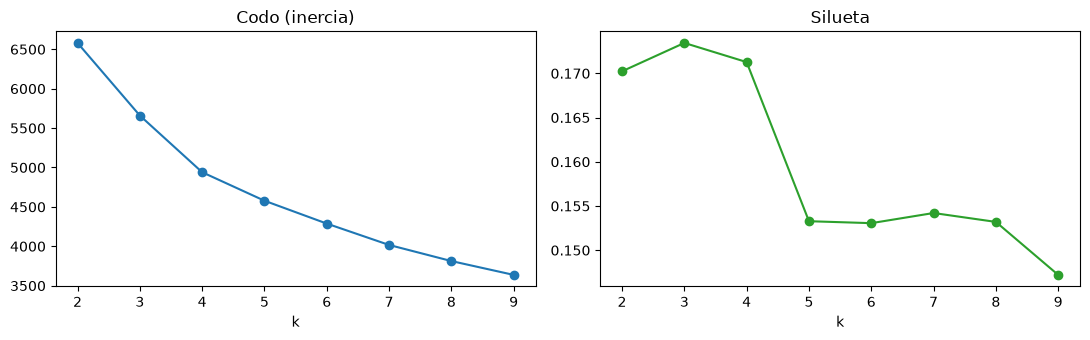

,inercia,silueta
2,6580.662,0.170
3,5659.386,0.173
4,4940.144,0.171
5,4578.395,0.153
6,4288.230,0.153
7,4017.105,0.154
8,3812.744,0.153
9,3637.146,0.147


In [11]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

VARS = ["n_pedidos", "ventas_total", "ticket_promedio", "flete_relativo", "tasa_retraso", "n_categorias", "dias_despacho", "calificacion_promedio"]
COLA_LARGA = ["n_pedidos", "ventas_total", "ticket_promedio", "n_categorias", "dias_despacho"]
x = vend[VARS].copy()
x[COLA_LARGA] = np.log1p(x[COLA_LARGA])
Z = StandardScaler().fit_transform(x)

codo = {}
for k in range(2, 10):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z)
    codo[k] = {"inercia": km.inertia_, "silueta": silhouette_score(Z, km.labels_)}
codo = pd.DataFrame(codo).T
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(codo.index, codo["inercia"], "o-"); ax[0].set_title("Codo (inercia)"); ax[0].set_xlabel("k")
ax[1].plot(codo.index, codo["silueta"], "o-", color="tab:green"); ax[1].set_title("Silueta"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
codo.round(3)

**Elección de k.** El codo no es claro y la silueta es baja (≈ 0,17 para k = 3 y k = 4, casi iguales): los vendedores forman una nube continua más que grupos separados. Se elige **k = 4** por criterio de negocio: con 3 grupos se mezclan los vendedores con muchos retrasos con los demás, y con 4 aparece un segmento accionable (los lentos y con quejas).

In [12]:
km = KMeans(n_clusters=4, n_init=50, random_state=42).fit(Z)
vend["segmento"] = km.labels_
perfil = vend.groupby("segmento")[VARS].median().round(2)
perfil.insert(0, "vendedores", vend.groupby("segmento").size())

def nombrar(perfil):
    """Nombra cada segmento por su perfil (reglas sobre las medianas), no por su número."""
    nombres, libres = {}, set(perfil.index)
    for nombre, fila in [("Grandes de volumen", perfil["n_pedidos"].idxmax()), ("En riesgo: lentos y con quejas", perfil["tasa_retraso"].idxmax())]:
        nombres[fila] = nombre; libres.discard(fila)
    nombres[perfil.loc[sorted(libres)]["flete_relativo"].idxmax()] = "Ticket bajo y flete pesado"
    for i in perfil.index: nombres.setdefault(i, "Pequeños de ticket alto y buen servicio")
    return nombres

ACCIONES = {
    "Grandes de volumen": "Cuentas clave: gestor asignado, condiciones de flete por volumen y vigilancia de la calidad.",
    "En riesgo: lentos y con quejas": "Plan de mejora: meta de despacho en 3 días, aviso de retraso al cliente y revisión mensual.",
    "Ticket bajo y flete pesado": "Combos o envío agrupado para bajar el flete relativo y mínimo de compra.",
    "Pequeños de ticket alto y buen servicio": "Impulsarlos: más visibilidad y publicidad, porque cumplen bien y cada venta deja más.",
}
nombres = nombrar(perfil)
vend["nombre_segmento"] = vend["segmento"].map(nombres)
perfil["nombre_segmento"] = perfil.index.map(nombres)
perfil["accion"] = perfil["nombre_segmento"].map(ACCIONES)
perfil.sort_values("vendedores", ascending=False)

,vendedores,n_pedidos,ventas_total,ticket_promedio,flete_relativo,tasa_retraso,n_categorias,dias_despacho,calificacion_promedio,nombre_segmento,accion
segmento,,,,,,,,,,,
0,357,23.0,3894.63,156.31,0.14,0.05,2.0,2.39,4.28,Pequeños de ticket alto y buen servicio,"Impulsarlos: más visibilidad y publicidad, por..."
1,244,22.0,1217.90,53.33,0.35,0.06,2.0,2.45,4.19,Ticket bajo y flete pesado,Combos o envío agrupado para bajar el flete re...
2,242,123.5,12566.53,108.15,0.21,0.07,4.0,2.86,4.10,Grandes de volumen,"Cuentas clave: gestor asignado, condiciones de..."
3,162,22.5,3462.52,132.87,0.19,0.17,2.0,5.08,3.62,En riesgo: lentos y con quejas,"Plan de mejora: meta de despacho en 3 días, av..."


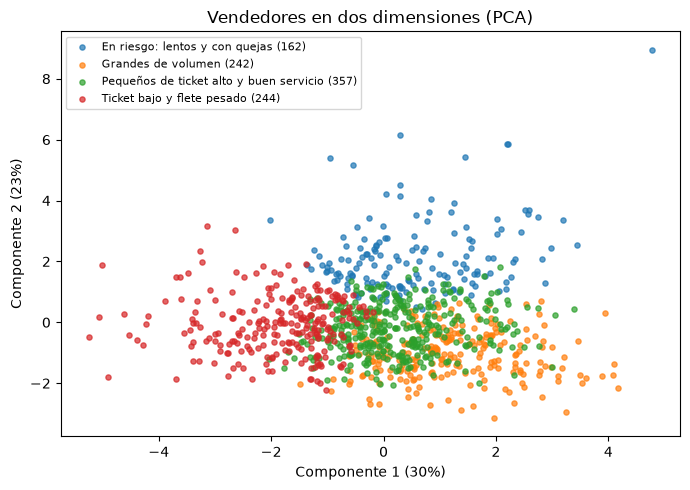

In [13]:
pca = PCA(n_components=2, random_state=42).fit(Z)
xy = pca.transform(Z)
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, g in vend.groupby("nombre_segmento"):
    ax.scatter(xy[g.index, 0], xy[g.index, 1], s=14, alpha=0.7, label=f"{nombre} ({len(g)})")
ax.legend(fontsize=8); ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%})"); ax.set_title("Vendedores en dos dimensiones (PCA)")
plt.tight_layout(); plt.show()

**Perfiles y acciones.** *Pequeños de ticket alto y buen servicio* (357 vendedores): pocos pedidos, ticket de unos 156, despachan en 2,4 días y casi no se retrasan. *Ticket bajo y flete pesado* (244): ticket de unos 53 y flete del 35 % del precio. *Grandes de volumen* (242): ≈ 123 pedidos y ≈ 12.500 en ventas, con 4 categorías. *En riesgo: lentos y con quejas* (162): 17 % de entregas tardías, 5 días para despachar y calificación de 3,6. La acción de cada uno está en la tabla de arriba.

## Parte 4 · Deep learning: sentimiento de los comentarios

Clasifiquen una muestra de comentarios con un modelo preentrenado de Hugging Face que entienda portugués y compárenlo con las estrellas. Activen la GPU de Colab para que sea rápido.

In [14]:
!pip install -q transformers

In [15]:
import torch
from transformers import pipeline

consulta_comentarios = """
    SELECT DISTINCT ON (order_id) order_id, review_score AS estrellas, review_comment_message AS comentario
    FROM final.order_reviews
    WHERE review_comment_message IS NOT NULL AND LENGTH(TRIM(review_comment_message)) > 0
    ORDER BY order_id, review_answer_timestamp DESC"""
todos = pd.read_sql(consulta_comentarios, motor)
muestra = todos.sample(1500, random_state=42).reset_index(drop=True)   # semilla fija, más de 1.000 comentarios
print("comentarios con texto:", len(todos), "| muestra:", len(muestra))

dispositivo = 0 if torch.cuda.is_available() else -1                   # GPU si hay (Colab: T4)
clasificador = pipeline("sentiment-analysis", model="cardiffnlp/twitter-xlm-roberta-base-sentiment", device=dispositivo)
salida = clasificador(muestra["comentario"].tolist(), batch_size=32, truncation=True, max_length=256)
muestra["sentimiento"] = [s["label"].lower() for s in salida]
muestra["confianza"] = [round(s["score"], 3) for s in salida]
GRUPO = {1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"}
muestra["estrellas_agrupadas"] = muestra["estrellas"].map(GRUPO)
muestra["coincide"] = muestra["sentimiento"] == muestra["estrellas_agrupadas"]
muestra.to_csv("sentimiento_muestra.csv", index=False)
cruce = pd.crosstab(muestra["estrellas"], muestra["sentimiento"]).reindex(columns=["negative", "neutral", "positive"], fill_value=0)
print("Coincidencia con las estrellas:", round(muestra["coincide"].mean(), 4), "| dispositivo:", "GPU" if dispositivo == 0 else "CPU")
cruce

W1103 09:56:31.841000 4316 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


comentarios con texto: 33458 | muestra: 1500


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 25225.31it/s]

Coincidencia con las estrellas: 0.708 | dispositivo: GPU


sentimiento,negative,neutral,positive
estrellas,,,
1,219,95,9
2,51,35,5
3,54,43,23
4,37,56,150
5,26,98,599


Las estrellas se agruparon igual que el modelo: 1–2 negativo, 3 neutro, 4–5 positivo.

In [16]:
pd.set_option("display.max_colwidth", 140)
desacuerdos = pd.read_csv("desacuerdos_clasificados.csv")   # 14 casos leídos y clasificados a mano (ver abajo)
desacuerdos[["caso", "estrellas", "sentimiento_modelo", "comentario", "quien_se_equivoca", "explicacion"]]

,caso,estrellas,sentimiento_modelo,comentario,quien_se_equivoca,explicacion
0,1337,5,negative,"Só uma sugestão, saiam por favor da logística doa correios, pois o serviço que eles prestam é um lixo. Quanto a loja nota 10 o produto e...",Mixto,Elogia a la tienda («nota 10») y critica a Correios. El cliente calificó la tienda; el modelo se quedó con lo negativo.
1,1230,5,negative,Cobraram 2 fretes para mesmo produto pois tinha comprado 2 unidades achei isso muita sacanagem !!!,Cliente,Se queja de que le cobraron dos fletes y aun así puso 5 estrellas. El modelo acierta: el texto es negativo.
2,150,5,negative,"Comprei e não recebi, tá se tornando rotina, vocês vão perder seus clientes",Cliente,«Compré y no recibí»: es una queja clara. Probablemente marcó 5 estrellas por error. El modelo acierta.
3,560,5,negative,pena que o prazo foi longo,Mixto,"Queja leve («lástima que el plazo fue largo»). Las estrellas reflejan el producto y el texto, el plazo: ambos tienen parte de razón."
4,777,5,negative,"Loja boa, pena q aconteceu esse emprego São.",Modelo,"«Tienda buena, lástima que…»: frase confusa y coloquial. Los elogios pesan más que el lamento, pero el modelo se fue al negativo."
5,602,1,positive,Superou as expectativas...,Cliente,«Superó las expectativas» con 1 estrella: estrellas probablemente invertidas. El modelo acierta.
6,458,1,positive,Produto ...bom..como eu esperava..com o no anúncio,Cliente,"«Producto bueno, como esperaba y como el anuncio» con 1 estrella: error del cliente al calificar."
7,948,1,positive,Espero mais dedicação nas proximas entregas,Modelo,Queja cortés («espero más dedicación en las próximas entregas»): el modelo la leyó como positiva; las estrellas tienen razón.
8,662,1,positive,"preço bom, entrega no prazo",Cliente,"«Buen precio, entrega a tiempo» con 1 estrella: texto positivo con calificación contradictoria."
9,103,1,positive,Estou no aguardo do meu produto!!,Modelo,«Estoy esperando mi producto»: es un reclamo por falta de entrega; los signos de exclamación engañaron al modelo.


### Preguntas

1. ¿En qué porcentaje coincide el sentimiento con las estrellas? ¿Dónde está la mayor confusión?
2. Muestren al menos 5 desacuerdos y clasifíquenlos: ¿error del modelo o del cliente?
3. ¿Qué dice el texto que las estrellas no dicen?

### Respuestas

**1. ¿En qué porcentaje coincide el sentimiento con las estrellas? ¿Dónde está la mayor confusión?** Coincide en **70,8 %** de los 1.500 comentarios (ver tabla cruzada arriba). Lo más fácil es el extremo positivo: de 723 comentarios de 5 estrellas, 599 salen positivos. La mayor confusión es con **lo neutro**: 98 comentarios de 5 estrellas y 95 de 1 estrella se clasifican como neutros, porque son textos que describen un hecho («llegó antes del plazo», «ya pasó la fecha de entrega») sin adjetivos.

**2. Desacuerdos.** Se leyeron 14 casos (tabla de arriba): el **modelo** se equivoca en 6 (quejas implícitas o corteses, frases confusas, signos de exclamación), el **cliente** en 5 (puso 1 estrella y escribió «superó las expectativas», o 5 estrellas y se quejó de que no recibió), 2 son **mixtos** y 1 no es error de nadie (una pregunta).

**3. ¿Qué dice el texto que las estrellas no dicen?** La **causa**: el transportista (Correios), el flete cobrado dos veces, el pedido incompleto, el plazo. Las estrellas solo dicen cuánto molestó; el texto dice por qué. Para Olist sirve para separar problemas del vendedor, del transportista y de la plataforma, y para encontrar clientes que puntúan alto pero se quejaron.

## Extra (opcional, +5) · Red neuronal contra XGBoost

Misma división por fecha y mismas variables. Muestren la curva de pérdida y expliquen el resultado.

**No se hizo el extra (red neuronal contra XGBoost, +5):** es opcional y no se realizó.

## Parte 5 · Despliegue

- URL de la API en Render: **https://olist-riesgo-api-aaxd.onrender.com**
- URL de la app de Streamlit: **https://olist-riesgo-resenas.streamlit.app**

Versiones de este entorno (para su `requirements.txt` de la API):

In [17]:
import sklearn, xgboost
print(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}")

pandas==3.1.0
numpy==2.5.4
scikit-learn==1.9.1
xgboost==3.4.1


Prueba de la API desplegada (debe devolver una probabilidad):

In [18]:
import requests
URL_API = "https://olist-riesgo-api-aaxd.onrender.com"
pedido = pedidos[CONTRATO[:-1]].head(1).astype(object).where(pedidos[CONTRATO[:-1]].head(1).notna(), None).iloc[0].to_dict()
pedido = {k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in pedido.items()}
requests.post(URL_API + "/riesgo", json=pedido, timeout=90).json()

{'probabilidad': 0.7698, 'riesgo_alto': True, 'umbral': 0.329}

## Parte 6 · Ficha del modelo

La ficha va en `ficha_modelo.md` (también se muestra en la página «Ficha del modelo» de la app).

- API en Render: https://olist-riesgo-api-aaxd.onrender.com
- App en Streamlit: https://olist-riesgo-resenas.streamlit.app

## Uso de IA

Usé herramientas de inteligencia artificial como apoyo para escribir y probar el código y los textos de este proyecto. Cada decisión (validación por fecha, métrica, umbral, k de K-Means, modelo de sentimiento) está explicada en este cuaderno y en la ficha del modelo.